# Task 1

In [12]:
import numpy as np
import pygad
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
def read_txt_to_dict(path):

    # Dictionary
    slovar = dict()

    # Open the file
    with open(path, 'r') as file:
        
        for line in file:
            
            # Cleaning the line
            splited = line.replace(",", "").replace("[", "").replace("]", "").replace("\n", "").split()
            
            # Filling dictionary
            slovar[splited[0]] = splited[1:]
            
    return slovar

In [ ]:

def load_data(folder):

    classes = read_txt_to_dict(f"{folder}\\Classes.txt")
    classrooms = read_txt_to_dict(f"{folder}\\Classrooms.txt")
    teachers = read_txt_to_dict(f"{folder}\\Teachers.txt")

    print("classes:",classes)
    print("classrooms:", classrooms)
    print("teachers:",teachers)
    print()

    idClasses = []
    globalIdClassDictionary = {}
    slovarTrajanjaUr = {}
    # lecture id -> class index, For more lectures of same class -> to know from which class 
    lectureClass = {} 
    idLecture = 0
    indexClass = {}

    for id, nameClass in enumerate(classes):
        # Duration of specific lecture in class
        for duration in classes[nameClass]: 
            idClasses.append(idLecture)
            slovarTrajanjaUr[idLecture] = int(duration)
            lectureClass[idLecture] = id
            # Class name - hourTime - id
            globalIdClassDictionary[idLecture] = f"{nameClass}-{idLecture} ({duration})"
            idLecture+=1

        # added class index - for teachers
        indexClass[nameClass] = id


    # Classroom Index: 0:P1, 1:P2, 2:P3, 3:P4
    # classroomTime: on index x is start_time and end_time
    idClassroom = []
    classroomTime = []
    globalIdClassroomsDictionary = {}

    for id, clas in enumerate(classrooms):
        # Duration (from when to when open)
        c = classrooms[clas]
        classroomTime.append([int(c[0]), int(c[1])])

        globalIdClassroomsDictionary[id] = f"{clas} ({c[0]}-{c[1]})"

        idClassroom.append(id)

    # Teacher Index: Anna:0, Brian:1, Charles:2, Diana:3
    # teacherClass: on index x are avaible classes that that teacher teachs (ony the first index x)
    idTeacher = []
    teacherClass = []
    globalIdTeachersDictionary = {}

    for id, t in enumerate(teachers):
        idTeacher.append(id)

        globalIdTeachersDictionary[id] = t

        # Which lectures indexed for teachers
        h = []
        for lecture in teachers[t]:
            # Index of a class
            # {"Programming":0, "Math":1, "Algorithms":2, "OperatingSystems":3}
            h.append(indexClass[lecture])

        teacherClass.append(h)


    return (idClasses, slovarTrajanjaUr, lectureClass, globalIdClassDictionary,
            idClassroom, classroomTime, globalIdClassroomsDictionary,
            idTeacher, teacherClass, globalIdTeachersDictionary)


(idClasses, slovarTrajanjaUr, lectureClass, globalIdClassDictionary,
idClassroom, classroomTime, globalIdClassroomsDictionary,
idTeacher, teacherClass, globalIdTeachersDictionary) = load_data("Data")

print("idClasses:", idClasses, " -  SlovarTrajanjaUr:", slovarTrajanjaUr)
print("idClassroom:", idClassroom, " -  classroomTime" ,classroomTime)
print("idTeacher:", idTeacher, " -  teacherClass:", teacherClass)
print("lectureClass:", lectureClass,"\n")

# For decoding
print("globalIdClassDictionary", globalIdClassDictionary)
print("globalIdClassroomsDictionary", globalIdClassroomsDictionary)
print("globalIdTeachersDictionary", globalIdTeachersDictionary)

classes: {'Programming': ['2', '3', '2', '2'], 'Math': ['2', '2'], 'Algorithms': ['2', '3'], 'OperatingSystems': ['2', '2']}
classrooms: {'P1': ['10', '16'], 'P2': ['8', '16'], 'P3': ['10', '16'], 'P4': ['10', '16']}
teachers: {'Anna': ['Programming', 'Math'], 'Brian': ['Programming', 'Algorithms', 'OperatingSystems'], 'Charles': ['Math'], 'Diana': ['Algorithms', 'OperatingSystems']}

idClasses: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]  -  SlovarTrajanjaUr: {0: 2, 1: 3, 2: 2, 3: 2, 4: 2, 5: 2, 6: 2, 7: 3, 8: 2, 9: 2}
idClassroom: [0, 1, 2, 3]  -  classroomTime [[10, 16], [8, 16], [10, 16], [10, 16]]
idTeacher: [0, 1, 2, 3]  -  teacherClass: [[0, 1], [0, 2, 3], [1], [2, 3]]
lectureClass: {0: 0, 1: 0, 2: 0, 3: 0, 4: 1, 5: 1, 6: 2, 7: 2, 8: 3, 9: 3} 

globalIdClassDictionary {0: 'Programming-0 (2)', 1: 'Programming-1 (3)', 2: 'Programming-2 (2)', 3: 'Programming-3 (2)', 4: 'Math-4 (2)', 5: 'Math-5 (2)', 6: 'Algorithms-6 (2)', 7: 'Algorithms-7 (3)', 8: 'OperatingSystems-8 (2)', 9: 'OperatingSystems-

In [ ]:
# From https://pygad.readthedocs.io/en/latest/custom_functions.html
import time

# How quickly does the fitness score increase
fitnessScores = []

# Adding time to a dictionary
timeDictionary = {
    "overhead": 0, "parents": 0, "crossover": 0, "mutation": 0, "fitness": 0,
    "latest_call_back": 0
}

# When GA starts
def on_start(ga_instance):
    fitnessScores.clear()
    # Reseting to zero
    for key in timeDictionary:
        timeDictionary[key] = 0
    # Setting the time when GA starts
    timeDictionary["latest_call_back"] = time.perf_counter()

# When fitness score is calculated
def on_fitness(ga_instance, last_gen_fitness):

    call_back = time.perf_counter()
    # call_back - latest_call_back = time that it took to complete this step!
    # We sum together, average in the end
    timeDictionary["overhead"] += call_back - timeDictionary["latest_call_back"]
    
    # Save last callback
    timeDictionary["latest_call_back"] = call_back

# After parents selection
def on_parents(ga_instance, last_gen_parents):
    
    call_back = time.perf_counter()
    timeDictionary["parents"] += call_back - timeDictionary["latest_call_back"]
    timeDictionary["latest_call_back"] = call_back

# After crossover is finished
def on_crossover(ga_instance, last_gen_offspring):
    
    call_back = time.perf_counter()
    timeDictionary["crossover"] += call_back - timeDictionary["latest_call_back"]
    timeDictionary["latest_call_back"] = call_back

# After mutation
def on_mutation(ga_instance, last_gen_offspring):
        
    call_back = time.perf_counter()
    timeDictionary["mutation"] += call_back - timeDictionary["latest_call_back"]
    timeDictionary["latest_call_back"] = call_back

# At the end of the generation
# fitness time calculated before on_generation and it fell into generation bucket
def on_generation(ga_instance):

    call_back = time.perf_counter()
    timeDictionary["fitness"] += call_back - timeDictionary["latest_call_back"]
    timeDictionary["latest_call_back"] = call_back

    # gives max fitness 
    fitnessScores.append(ga_instance.last_generation_fitness.max())

In [ ]:
# suitable fitness function that will reward schedules that satisfy the conditions and penalize those that do not.
def f(schedule):

    # (idClass, idClassroom, start, idteacher)

    # Global count fitness score
    issue = 0

    # • Every lecture in the classes file must be present in the schedule
    for cid in idClasses:
        find = 0    
        
        # Find if exists 
        for lecture in schedule:
            if lecture[0] == cid: 
                find += 1
            
        # If one lecture/class is not found penatly is high
        if find == 0: 
            issue += 10

        # If some duplicates
        if find > 1:
            issue += 10


    # Every lecture needs to be assigned to a classroom at a time when that classroom is available. 
    # Filled spots (za vsako učilnico toliko pozicij kot ur)
    # Array is build 0 - unocupied , 1 - occupied and >1 means more lectures same time
    spots = [ [ 0 for j in range(razred[1]-razred[0])] for razred in classroomTime]
    

    # Teachers hours (from 0 to 24) -> that many spots
    teacherSpots = [ [0 for j in range(24)] for _ in idTeacher]

    for lec in schedule:
                
        id_Class, id_Classroom, startHour, id_Teacher = lec

        # You cannot index by float round number
        id_Class, id_Classroom, startHour, id_Teacher = int(id_Class), int(id_Classroom), int(startHour), int(id_Teacher)
    
        # From slovar of hours, I get duration of this class
        endHour = startHour + slovarTrajanjaUr[id_Class]
    
        # What index should it fill (Normalizing so it starts with 0 - for array)
        startIndToFill = startHour - classroomTime[id_Classroom][0]
        endIndToFill = endHour - classroomTime[id_Classroom][0]

        # For how many hours the classroom is open
        dolg = classroomTime[id_Classroom][1] - classroomTime[id_Classroom][0]

        # if the class starts before the classroom opens - penatly (that many hours that is late - increment issue)
        if startHour < classroomTime[id_Classroom][0]:       
            issue += abs(classroomTime[id_Classroom][0] - startHour) * 6

        # if class goes longer than the classroom is open. (14-17) = 14,15,16   
        if endHour > classroomTime[id_Classroom][1]:
            issue += (endHour - classroomTime[id_Classroom][1]) * 6
        
        validStart = max(startIndToFill, 0)
        validEnd = min(endIndToFill, dolg)
       
        # Fill the spots and check for overlaping 
        # 10-12 -> increments 10, 11
        for i in range(validStart, validEnd):
            spots[id_Classroom][i]+=1

            # Lectures cannot overlap in the same classroom: a single classroom can hold only a single lecture in a given hour.
            # For every value that is more than 1 -> *3 per overlap
            if spots[id_Classroom][i] > 1: issue += 3 * (spots[id_Classroom][i] - 1)

        # Teachers cannot teach more than one lecture at the same time. (So across all the classrooms in a day)
        for i in range(startHour, min(endHour, 24)):
            # If teacher already has a class at that hour
            if teacherSpots[id_Teacher][i] > 0:
                issue += 3
            teacherSpots[id_Teacher][i] += 1

        # Every lecture needs to be assigned a teacher (That teaches that class) 
        # Which classes can the teacher teach
        canTeach = teacherClass[id_Teacher]
        teachingClass = lectureClass[id_Class]

        if teachingClass not in canTeach:
            issue+=10

    

        
    return issue

# Negating the value to minimize the fitness_score (in this case error rate)
def fitness_function(ga_instance, solution, x_idx):

    # solution is flat so I had to make it 2D, for each lecture in a solution
    schedule = [solution[i:i+4] for i in range(0, len(solution), 4)]

    return -f(schedule)




In [17]:

# For each diff class id -> have a prebuilt gene space (idClass, idClassroom, start, idteacher)
earliest = min(t[0] for t in classroomTime)   # 8
latest   = max(t[1] for t in classroomTime)   # 16
startHours = list(range(earliest, latest))    # [8,..,15]

gene_space = []
for _ in range(len(idClasses)):
    # Extending array further 
    gene_space.extend([
        idClasses,
        idClassroom,
        # end hour will be calculated in fitness
        startHours,
        idTeacher
    ])


# Genetic Algorithm (sol_per_pop - how many solutions exist in each generation.)
num_gener = 200
ga_instance = pygad.GA(
    fitness_func=fitness_function, 
    num_generations=num_gener,
    num_parents_mating=10,
    sol_per_pop=50,
    num_genes = len(gene_space),
    gene_space = gene_space,
    # Uniform crossover - generates a mask of length num_genes and gives it 0 or 1 -> 0 for gen from 1. parent and 1 for gen from 2. parent
    crossover_type = "uniform",

    # Swaping 2 genes (Swaps that break gene space are rejected)
    mutation_type='swap',  

    # Same teacher for 2 objects, but different class/hour
    allow_duplicate_genes=True,
    
    # Same seed -> so results reproducible
    random_seed=14,

    # Callbaks
    on_start=on_start,
    on_fitness=on_fitness,
    on_parents=on_parents,
    on_crossover=on_crossover,
    on_mutation=on_mutation,
    on_generation=on_generation) 

ga_instance.run()


solution, solution_fitness, solution_idx = ga_instance.best_solution()
print("Best parameter", solution)
print("Fitness", solution_fitness)
print("Index", solution_idx)

# REVIEW: For running seed from 0-20:
#   - i think best was -3 at seed 14
#   - most between -9 to -36 which means some major rules were broken
#       (duplicate lectures/teachers, ...)
# Conclusion: OK for task 1 since it only needs to work -> we will compare to task 2 later


Best parameter [ 0.  0. 10.  1.  4.  0. 14.  2.  7.  1. 11.  3.  9.  1.  9.  3.  1.  2.
 13.  0.  8.  3. 12.  1.  2.  1.  8.  1.  3.  3. 10.  0.  5.  2. 10.  2.
  6.  1. 14.  1.]
Fitness -3
Index 0


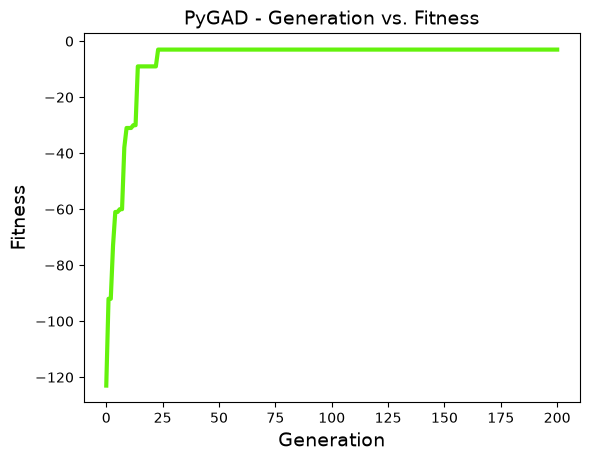

In [18]:
ga_instance.plot_fitness();

In [19]:
def display_schedule(schedule):

    # Group lectures by classroom ID (so to sort them out)
    classrooms = {}
    for lec in schedule:
        
        idClass, idClassroom, startHour, idTeacher = lec
        # You cannot index by float round number
        idClass, idClassroom, startHour, idTeacher = int(idClass), int(idClassroom), int(startHour), int(idTeacher)

        # Saving all hours to a specific classroom - here we didn't yet found it
        if idClassroom not in classrooms:
            classrooms[idClassroom] = []

        #
        classrooms[idClassroom].append((startHour, idClass, idTeacher))


    # Sort classrooms by ID for output
    for idClassroom in sorted(classrooms.keys()):

        # Names
        classroomName = globalIdClassroomsDictionary[idClassroom]
        
        print(f"\n{classroomName}")
        print("-" * 40)
        
        # Sort lectures in this classroom by start hour (in order)
        lectures = sorted(classrooms[idClassroom], key=lambda x: x[0])

        for start_hour, id_class, id_teacher in lectures:

            # Decoding from indexes to names
            classsName = globalIdClassDictionary[id_class]
            teachername = globalIdTeachersDictionary[id_teacher]
            endHour = start_hour + slovarTrajanjaUr[id_class]

            # Text Representation
            print(f"  [ {start_hour:02d}:00 - {endHour:02d}:00 ] -> {classsName} (Taught by: {teachername})")

    
# we can notice -3 at P2 for overlap at 9-10
schedule = [solution[i:i+4] for i in range(0, len(solution), 4)]
display_schedule(schedule)


P1 (10-16)
----------------------------------------
  [ 10:00 - 12:00 ] -> Programming-0 (2) (Taught by: Brian)
  [ 14:00 - 16:00 ] -> Math-4 (2) (Taught by: Charles)

P2 (8-16)
----------------------------------------
  [ 08:00 - 10:00 ] -> Programming-2 (2) (Taught by: Brian)
  [ 09:00 - 11:00 ] -> OperatingSystems-9 (2) (Taught by: Diana)
  [ 11:00 - 14:00 ] -> Algorithms-7 (3) (Taught by: Diana)
  [ 14:00 - 16:00 ] -> Algorithms-6 (2) (Taught by: Brian)

P3 (10-16)
----------------------------------------
  [ 10:00 - 12:00 ] -> Math-5 (2) (Taught by: Charles)
  [ 13:00 - 16:00 ] -> Programming-1 (3) (Taught by: Anna)

P4 (10-16)
----------------------------------------
  [ 10:00 - 12:00 ] -> Programming-3 (2) (Taught by: Anna)
  [ 12:00 - 14:00 ] -> OperatingSystems-8 (2) (Taught by: Brian)


overhead: 0.0029 s -> avg per step: 0.0144 ms
parents: 0.0230 s -> avg per step: 0.1150 ms
crossover: 0.0412 s -> avg per step: 0.2061 ms
mutation: 3.9049 s -> avg per step: 19.5245 ms
fitness: 0.2170 s -> avg per step: 1.0848 ms


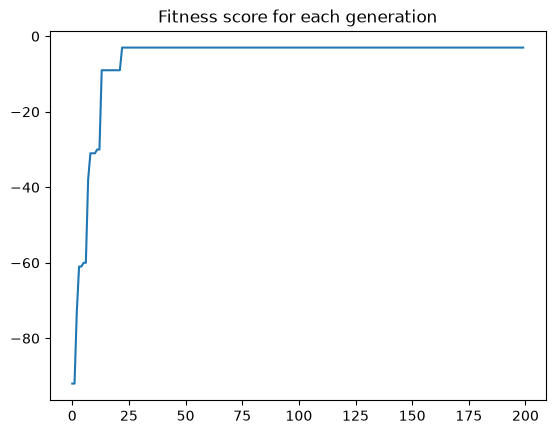

In [20]:
# Time of each step (lifecycle callbacks) <-> Average times
def printTimes():

    allTime = 0
    # For every callback
    for name, value in timeDictionary.items():

        # Ignore latest callback
        if name != "latest_call_back":
            
            # Averaging -> times
            avg = value / num_gener 
            allTime += value
            print(f"{name}: {value:.4f} s -> avg per step: {avg*1000:.4f} ms")

    # Ploting fitnes scores
    # print(fitnessScores)
    plt.plot(np.arange(0, len(fitnessScores)), fitnessScores)
    plt.title("Fitness score for each generation")
    plt.show()



printTimes()
# Review : 
# Mutation takes most of the time
# We chose mutation type=swap which takes 2 random genes -> since most of them break the gene_space
# it keeps trying other pairs and validating -> random would probably be better here